<a href="https://colab.research.google.com/github/laksamanaap/244107020021-machine-leaning-course-2026-/blob/main/JS07/JS07_TugasLab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score


DATA_PATH = "CC_Customer_Dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Ukuran dataset:", df.shape)
display(df.head())
print("\nInformasi dataset:")
df.info()
print("\nJumlah missing values per kolom:")
display(df.isnull().sum().to_frame("Missing Values"))

Ukuran dataset: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3



Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB

Jumlah missing values per kolom:


,Missing Values
Sl_No,0
Customer Key,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


## Persiapan fitur

In [2]:
features_2 = ["Avg_Credit_Limit", "Total_Credit_Cards"]
features_all = [
    "Avg_Credit_Limit",
    "Total_Credit_Cards",
    "Total_visits_bank",
    "Total_visits_online",
    "Total_calls_made"
]

missing_features = [c for c in features_all if c not in df.columns]
if missing_features:
    raise ValueError(f"Kolom berikut tidak ditemukan pada dataset: {missing_features}")

# pastikan fitur yang dipakai adalah numerik dan periksa missing values
print("Missing values pada fitur yang digunakan:")
display(df[features_all].isnull().sum().to_frame("Missing Values"))

if df[features_all].isnull().any().any():
    raise ValueError("Terdapat missing values pada fitur. Tangani missing values sebelum clustering.")

scaler_2 = StandardScaler()
X2_scaled = scaler_2.fit_transform(df[features_2])

scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(df[features_all])

Missing values pada fitur yang digunakan:


,Missing Values
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


## 2. Scatterplot Avg_Credit_Limit vs Total_Credit_Cards

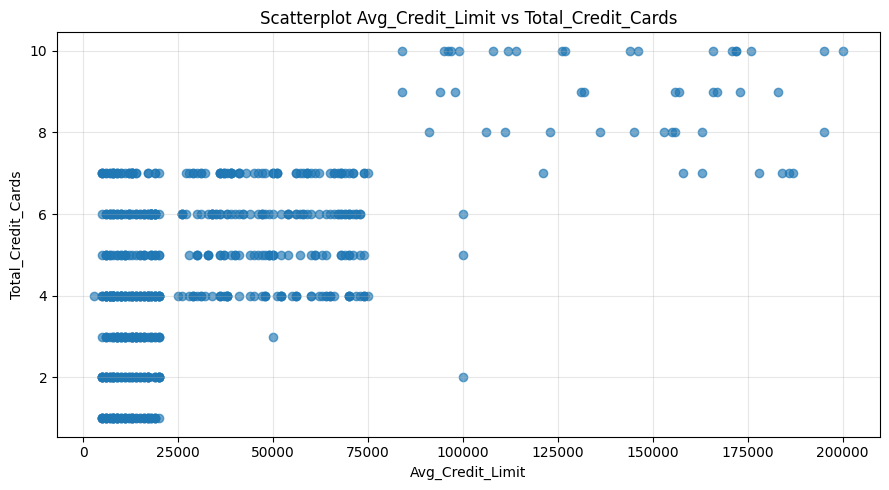

Korelasi Pearson: 0.6089


In [3]:
x = df["Avg_Credit_Limit"]
y = df["Total_Credit_Cards"]
correlation = x.corr(y)

plt.figure(figsize=(9, 5))
plt.scatter(x, y, alpha=0.65)
plt.xlabel("Avg_Credit_Limit")
plt.ylabel("Total_Credit_Cards")
plt.title("Scatterplot Avg_Credit_Limit vs Total_Credit_Cards")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Korelasi Pearson: {correlation:.4f}")

## 3. K-Means dengan dua fitur dan elbow method


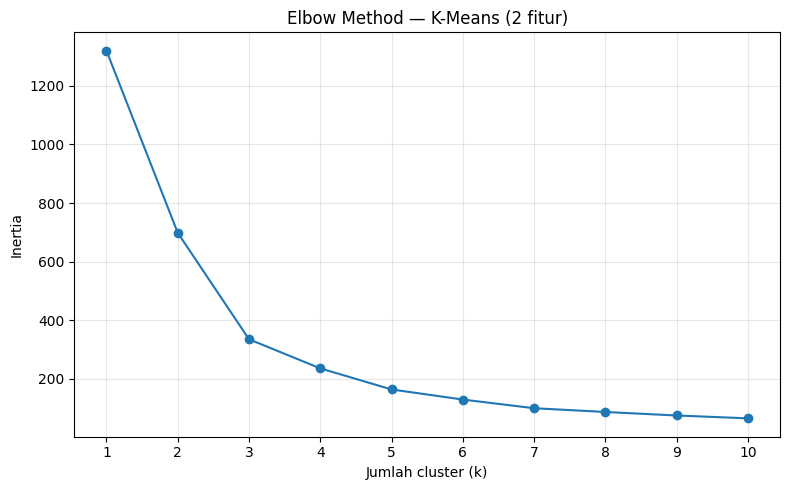

,k,Inertia
0,1,1320.000
1,2,698.293
2,3,334.724
3,4,235.393
4,5,163.472
5,6,128.964
6,7,99.370
7,8,86.534
8,9,74.530
9,10,64.826


In [4]:
inertia_2 = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X2_scaled)
    inertia_2.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertia_2, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method — K-Means (2 fitur)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"k": list(k_values), "Inertia": inertia_2}).round(3))

## 4. Visualisasi hasil K-Means

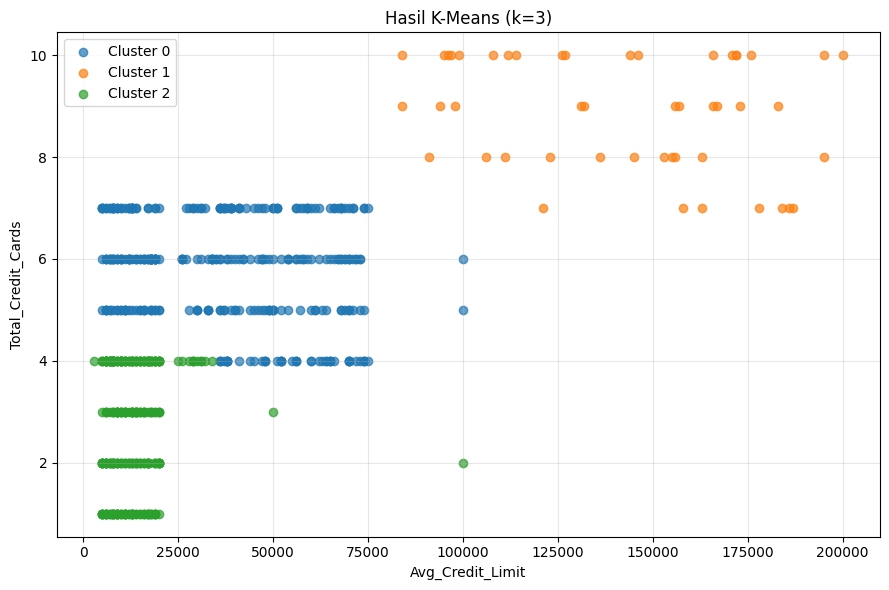

Jumlah anggota per cluster:


,Jumlah Pelanggan
KMeans_Cluster_2F,
0,330
1,48
2,282


In [5]:
# Ubah nilai ini jika hasil elbow plot menunjukkan pilihan k lain.
BEST_K_2 = 3

kmeans_2 = KMeans(n_clusters=BEST_K_2, random_state=42, n_init=10)
df["KMeans_Cluster_2F"] = kmeans_2.fit_predict(X2_scaled)

plt.figure(figsize=(9, 6))
for cluster in sorted(df["KMeans_Cluster_2F"].unique()):
    subset = df[df["KMeans_Cluster_2F"] == cluster]
    plt.scatter(
        subset["Avg_Credit_Limit"],
        subset["Total_Credit_Cards"],
        alpha=0.7,
        label=f"Cluster {cluster}"
    )

plt.xlabel("Avg_Credit_Limit")
plt.ylabel("Total_Credit_Cards")
plt.title(f"Hasil K-Means (k={BEST_K_2})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Jumlah anggota per cluster:")
display(df["KMeans_Cluster_2F"].value_counts().sort_index().to_frame("Jumlah Pelanggan"))

Setiap warna menunjukkan label klaster yang diberikan K-Means. Bandingkan posisi kelompok berdasarkan limit kredit dan jumlah kartu kredit. Label angka klaster tidak menunjukkan peringkat atau urutan tertentu.

## 5. DBSCAN dengan seluruh fitur relevan


In [6]:
# nilai awal, evaluasi lagi berdasarkan k-distance plot di bawah.
EPS = 1.0
MIN_SAMPLES = 5

dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_all_scaled)

labels = df["DBSCAN_Cluster"]
n_clusters = len(set(labels) - {-1})
n_noise = int((labels == -1).sum())

print(f"Parameter: eps={EPS}, min_samples={MIN_SAMPLES}")
print("Jumlah cluster (tanpa noise):", n_clusters)
print("Jumlah noise:", n_noise)
print("\nJumlah anggota per label (-1 adalah noise):")
display(labels.value_counts().sort_index().to_frame("Jumlah Data"))

Parameter: eps=1.0, min_samples=5
Jumlah cluster (tanpa noise): 2
Jumlah noise: 18

Jumlah anggota per label (-1 adalah noise):


,Jumlah Data
DBSCAN_Cluster,
-1,18
0,608
1,34


## 6. Menentukan `eps` DBSCAN dengan k-distance plot


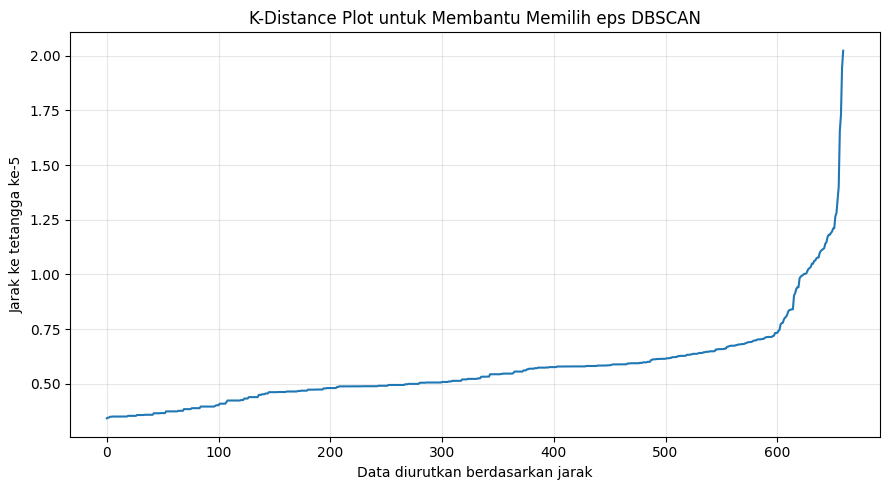

In [7]:
# Gunakan jumlah tetangga yang sama dengan MIN_SAMPLES.
neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES)
neighbors.fit(X_all_scaled)
distances, indices = neighbors.kneighbors(X_all_scaled)

# Kolom terakhir adalah jarak ke tetangga ke-MIN_SAMPLES.
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.xlabel("Data diurutkan berdasarkan jarak")
plt.ylabel(f"Jarak ke tetangga ke-{MIN_SAMPLES}")
plt.title("K-Distance Plot untuk Membantu Memilih eps DBSCAN")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Tambahan: elbow K-Means dengan seluruh lima fitur

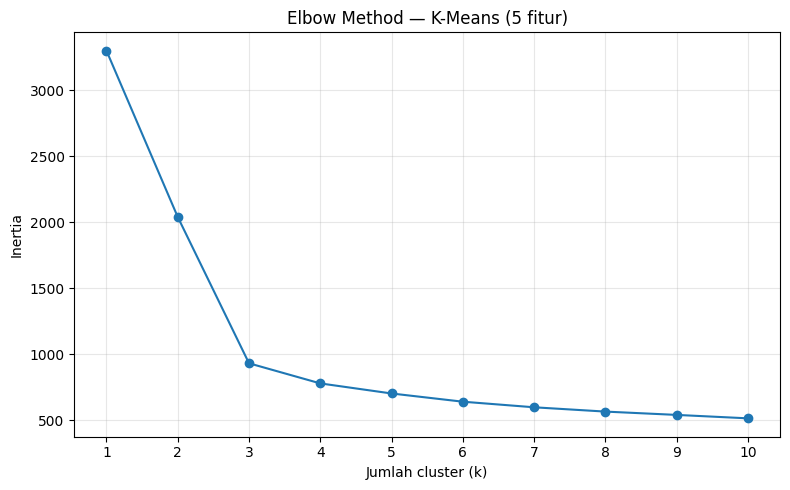

,k,Inertia
0,1,3300.000
1,2,2040.990
2,3,933.044
3,4,780.774
4,5,704.476
5,6,642.274
6,7,599.925
7,8,567.328
8,9,542.253
9,10,516.242


In [8]:
inertia_all = []
k_values_all = range(1, 11)

for k in k_values_all:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_all_scaled)
    inertia_all.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values_all), inertia_all, marker="o")
plt.xticks(list(k_values_all))
plt.xlabel("Jumlah cluster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method — K-Means (5 fitur)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"k": list(k_values_all), "Inertia": inertia_all}).round(3))

## 7. Silhouette Score dan Davies-Bouldin Index (DBI) untuk DBSCAN


In [9]:
labels_db = df["DBSCAN_Cluster"].to_numpy()
mask_non_noise = labels_db != -1

X_eval = X_all_scaled[mask_non_noise]
labels_eval = labels_db[mask_non_noise]
unique_clusters = np.unique(labels_eval)

print("Jumlah cluster non-noise:", len(unique_clusters))
print("Jumlah noise:", int((~mask_non_noise).sum()))
print("Proporsi noise: {:.2%}".format((~mask_non_noise).mean()))

if len(unique_clusters) >= 2 and len(labels_eval) > len(unique_clusters):
    sil = silhouette_score(X_eval, labels_eval)
    dbi = davies_bouldin_score(X_eval, labels_eval)
    print(f"Silhouette Score (tanpa noise): {sil:.4f}")
    print(f"Davies-Bouldin Index / DBI (tanpa noise): {dbi:.4f}")
else:
    print("Silhouette Score dan DBI tidak dapat dihitung secara valid: diperlukan minimal 2 cluster non-noise.")

Jumlah cluster non-noise: 2
Jumlah noise: 18
Proporsi noise: 2.73%
Silhouette Score (tanpa noise): 0.5680
Davies-Bouldin Index / DBI (tanpa noise): 0.6015


1. Scatterplot
Scatterplot menunjukkan hubungan positif antara Avg_Credit_Limit dan Total_Credit_Cards, dengan korelasi Pearson sebesar 0,6089. Namun, sebaran data tidak sepenuhnya linear karena titik-titik membentuk kelompok

2. K-Means dan Elbow Method
Berdasarkan grafik elbow, dipilih k = 3 karena penurunan inertia mulai melambat setelah tiga klaster

3. Hasil Klasterisasi K-Means
Dari 660 data pelanggan, terbentuk tiga klaster:
- Cluster 0: 330 pelanggan
- Cluster 1: 48 pelanggan
- Cluster 2: 282 pelanggan
Setiap klaster menunjukkan kelompok pelanggan dengan karakteristik limit kredit dan jumlah kartu kredit yang berbeda

4. Klasterisasi DBSCAN
DBSCAN menggunakan lima variabel yang telah distandardisasi dengan eps = 1.0 dan min_samples = 5. Hasilnya:
- Cluster 0: 608 data
- Cluster 1: 34 data
- Noise: 18 data

5. Penentuan Parameter
Elbow method pada K-Means dengan lima variabel menunjukkan kandidat k = 3. Untuk DBSCAN, k-distance plot digunakan menentukan kandidat eps berdasarkan titik perubahan kemiringan grafik

6. Evaluasi DBSCAN
- Silhouette Score: 0,5680
- DBI: 0,6015
Evaluasi dilakukan tanpa data noise. Hasilnya menunjukkan pemisahan klaster yang cukup baik, dengan nilai DBI yang relatif rendah

**Kesimpulan**
K-Means menghasilkan tiga klaster, sedangkan DBSCAN menghasilkan dua klaster dan 18 data noise. Kedua metode berhasil mengelompokkan pelanggan dengan pendekatan berbeda. DBSCAN juga mampu mendeteksi data noise, sedangkan K-Means mengharuskan jumlah klaster ditentukan terlebih dahulu